In [33]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [34]:
df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [35]:
X=df[['sepal_length','sepal_width']]
X.head()

,sepal_length,sepal_width
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6


In [36]:
#caling
scale=StandardScaler()
X_scaled=scale.fit_transform(X)

In [37]:
#slecting value of K
k=3

In [38]:
#Implementing K-Means
km=KMeans(
    n_clusters=k,
    max_iter=300,
    init='k-means++',
    random_state=42
)

In [39]:
km.fit(X_scaled)

#label
labels=km.labels_
labels[:75]

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2,
       2, 2, 2, 2, 2, 2, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 0, 1, 1, 1, 0], dtype=int32)

In [40]:
df["cluster"]=labels
df.head(150)

,sepal_length,sepal_width,petal_length,petal_width,species,cluster
0,5.1,3.5,1.4,0.2,setosa,2
1,4.9,3.0,1.4,0.2,setosa,2
2,4.7,3.2,1.3,0.2,setosa,2
3,4.6,3.1,1.5,0.2,setosa,2
4,5.0,3.6,1.4,0.2,setosa,2
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica,0
146,6.3,2.5,5.0,1.9,virginica,1
147,6.5,3.0,5.2,2.0,virginica,0
148,6.2,3.4,5.4,2.3,virginica,0


cluster visualize

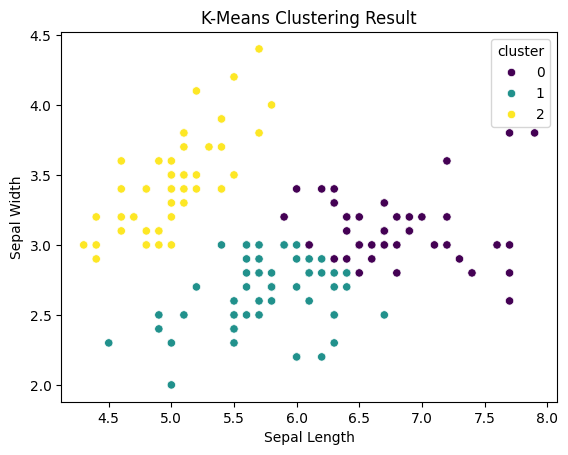

In [41]:
sns.scatterplot(x=df['sepal_length'],y=df['sepal_width'],hue=df['cluster'],palette='viridis')
plt.title("K-Means Clustering Result")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.show()

#Finding Optimal k (Elbow Method)

In [42]:
inertia_values=[]
k_range=range(1,11)
for k in k_range:
  km=KMeans(
      n_clusters=k,
      init='k-means++',
      random_state=42,
      )
  km.fit(X_scaled)
  inertia_values.append(km.inertia_)

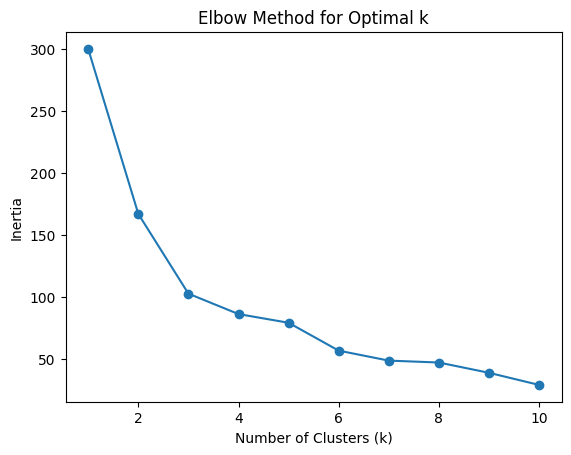

In [46]:
plt.plot(k_range,inertia_values,marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

# Model Evaluation (Silhouette Score)

In [47]:
score= silhouette_score(X_scaled, labels)
print("Silhouette Score:", score)

Silhouette Score: 0.43585870333974647
